# 02 · Paid Campaign Anomaly Detection & Root-Cause Analysis

**Business question:** in mid-July the marketing team saw paid-traffic results fall. Which campaign broke,
when, why, and what did it cost?

Approach: (1) automated daily CTR alert → (2) confirm the signal and rule out data problems →
(3) drill down by audience → (4) decompose the CTR drop into *audience-mix* vs *within-audience* effects →
(5) size the impact.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import db
import plot_style as ps

ps.apply()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
con = db.connect()

## 1. Campaign overview

In [2]:
overview = con.execute("""
    SELECT c.campaign_id, c.campaign_name, c.channel,
           SUM(impressions) AS impressions, SUM(clicks) AS clicks, SUM(a.orders) AS orders,
           ROUND(SUM(spend)) AS spend, ROUND(SUM(gmv)) AS gmv,
           ROUND(SUM(clicks) * 100.0 / SUM(impressions), 2) AS ctr_pct,
           ROUND(SUM(a.orders) * 100.0 / SUM(clicks), 2)    AS cvr_pct,
           ROUND(SUM(gmv) / SUM(spend), 2)                  AS roas
    FROM ad_performance a JOIN campaigns c USING (campaign_id)
    GROUP BY 1, 2, 3 ORDER BY 1
""").df()
overview

,campaign_id,campaign_name,channel,impressions,clicks,orders,spend,gmv,ctr_pct,cvr_pct,roas
0,C01,Brand Keywords,Paid Search,5203104.0,289136.0,27775.0,287497.0,2959672.0,5.56,9.61,10.29
1,C02,Category Keywords,Paid Search,10967977.0,364985.0,15690.0,572429.0,1663158.0,3.33,4.30,2.91
2,C03,Visitor Retargeting,Display Ads,9264756.0,300891.0,20476.0,379940.0,2179731.0,3.25,6.81,5.74
3,C04,Interest Audience Prospecting,Display Ads,43545492.0,612552.0,11217.0,475216.0,1190649.0,1.41,1.83,2.51
4,C05,New Product Launch - Health Food,Smart Campaign,3835237.0,89249.0,2974.0,101552.0,316811.0,2.33,3.33,3.12
5,C06,Mega-Sale Livestream Boost,Livestream/Influencer,1444677.0,56815.0,4059.0,101262.0,430819.0,3.93,7.14,4.25
6,C07,Singles' Day Livestream Boost,Livestream/Influencer,1732804.0,70557.0,5352.0,125364.0,573358.0,4.07,7.59,4.57
7,C08,Segment-Targeted Lookalike,Smart Campaign,3492847.0,112563.0,6482.0,153116.0,683069.0,3.22,5.76,4.46


## 2. Automated CTR-drop alert (`sql/03_campaign_daily_anomalies.sql`)
Rule: CTR ≥ 20% below the trailing 14-day median **and** more than 4 robust standard deviations below it.

In [3]:
daily = db.run(con, "03_campaign_daily_anomalies", z=4, min_drop=20)
daily["date"] = pd.to_datetime(daily["date"])
alerts = daily[daily["is_anomaly"]]
alerts[["date", "campaign_id", "impressions", "clicks", "spend", "ctr_pct", "ctr_median_14d_pct",
        "ctr_vs_median_pct", "ctr_robust_z"]]

,date,campaign_id,impressions,clicks,spend,ctr_pct,ctr_median_14d_pct,ctr_vs_median_pct,ctr_robust_z
376,2023-04-15,C02,34359.0,0.0,1746.22,0.000,3.348,-100.0,-23.1
767,2023-07-12,C03,42380.0,885.0,1024.90,2.088,3.299,-36.7,-8.2
768,2023-07-13,C03,43863.0,880.0,1062.26,2.006,3.299,-39.2,-8.8
769,2023-07-14,C03,41919.0,839.0,995.12,2.001,3.299,-39.3,-6.9
770,2023-07-15,C03,51133.0,1040.0,1211.97,2.034,3.283,-38.0,-5.2


Two separate issues fire:

| Alert | What the data shows | Diagnosis |
|---|---|---|
| **C02, 2023-04-15** | Impressions and spend normal, but **0 clicks, 0 visitors, 0 orders** | Click **tracking outage** — a data problem, not a performance problem. |
| **C03, from 2023-07-12** | Impressions up, clicks flat, CTR −35–40% | A real **performance drop** → investigate below. |

### 2a. C02 tracking outage — impute instead of reporting a fake drop

In [4]:
c02 = daily[daily["campaign_id"] == "C02"].set_index("date")
window = c02.loc["2023-04-08":"2023-04-22"]
baseline_ctr = window.drop(pd.Timestamp("2023-04-15"))["clicks"].sum() / window.drop(pd.Timestamp("2023-04-15"))["impressions"].sum()
imputed_clicks = round(c02.loc["2023-04-15", "impressions"] * baseline_ctr)
print(f"Surrounding-week CTR: {baseline_ctr:.2%}  ->  estimated clicks on 04-15: {imputed_clicks:,} (reported: 0)")

Surrounding-week CTR: 3.33%  ->  estimated clicks on 04-15: 1,144 (reported: 0)


## 3. C03 "Visitor Retargeting": what changed?

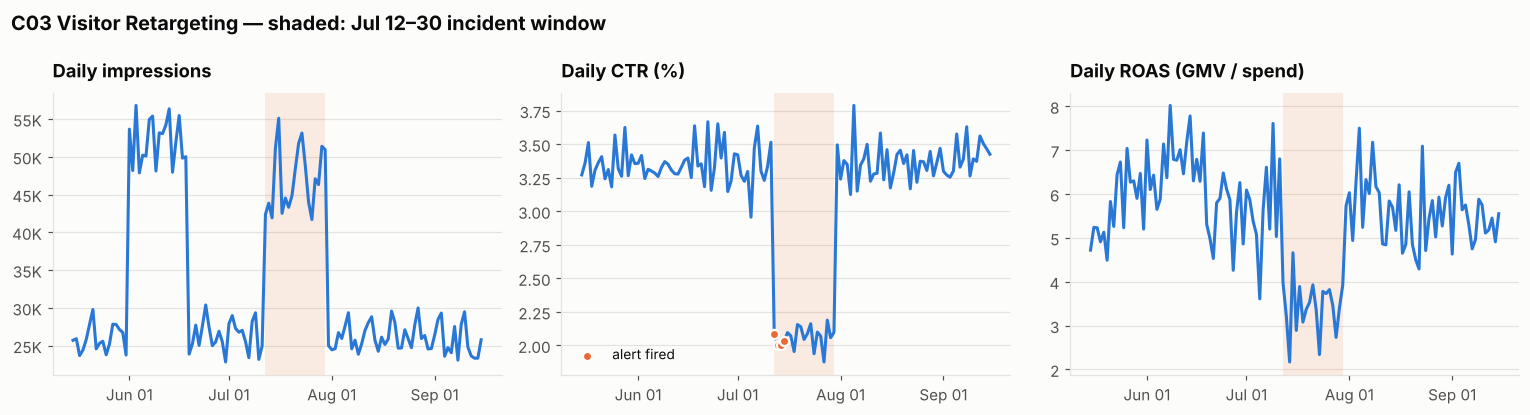

In [5]:
c03 = daily[daily["campaign_id"] == "C03"].set_index("date").loc["2023-05-15":"2023-09-15"]
ANOM_START, ANOM_END = pd.Timestamp("2023-07-12"), pd.Timestamp("2023-07-30")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for ax, col, title in zip(axes, ["impressions", "ctr_pct", "roas"],
                          ["Daily impressions", "Daily CTR (%)", "Daily ROAS (GMV / spend)"]):
    ax.axvspan(ANOM_START, ANOM_END, color=ps.ORANGE, alpha=0.12, lw=0)
    ax.plot(c03.index, c03[col], color=ps.BLUE)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
flagged = c03[c03["is_anomaly"]]
axes[1].scatter(flagged.index, flagged["ctr_pct"], s=36, color=ps.ORANGE, zorder=3,
                edgecolor=ps.SURFACE, linewidth=1.5, label="alert fired")
axes[1].legend(loc="lower left", fontsize=9)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))
fig.suptitle("C03 Visitor Retargeting — shaded: Jul 12–30 incident window", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
ps.save(fig, "02_c03_daily_kpis")

Impressions jumped while CTR and ROAS fell at the same moment and recovered abruptly on Jul 31.
A step change that starts and ends on specific days points to a **configuration change**, not to
gradual creative fatigue or seasonality (other campaigns were stable in the same window).

In [6]:
other = daily[(daily["campaign_id"] != "C03") & daily["date"].between("2023-06-19", "2023-07-30")].copy()
other["period"] = np.where(other["date"] >= ANOM_START, "Jul 12–30", "Jun 19–Jul 11")
(other.groupby(["campaign_id", "period"])[["clicks", "impressions"]].sum()
      .assign(ctr_pct=lambda d: (d.clicks / d.impressions * 100).round(2))["ctr_pct"].unstack())

period,Jul 12–30,Jun 19–Jul 11
campaign_id,,
C01,5.61,5.62
C02,3.34,3.34
C04,1.41,1.41
C05,NaN,2.35


## 4. Drill-down by audience (`sql/04_campaign_audience_mix.sql`)

In [7]:
mix = db.run(con, "04_campaign_audience_mix", campaign="C03",
             base_start="2023-06-19", base_end="2023-07-11",
             anom_start="2023-07-12", anom_end="2023-07-30")
mix["audience"] = mix["age_group"] + " · " + mix["city_tier"]
share = mix.pivot(index="audience", columns="period", values="impression_share_pct")
ctr = mix.pivot(index="audience", columns="period", values="ctr_pct")
summary = pd.DataFrame({
    "share_baseline_%": share["baseline"], "share_anomaly_%": share["anomaly"],
    "ctr_baseline_%": ctr["baseline"], "ctr_anomaly_%": ctr["anomaly"],
}).sort_values("share_anomaly_%", ascending=False)
summary.head(10)

,share_baseline_%,share_anomaly_%,ctr_baseline_%,ctr_anomaly_%
audience,,,,
18-24 · Tier 4+,0.61,27.24,1.519,1.413
18-24 · Tier 3,1.20,15.92,2.044,1.770
25-29 · Tier 4+,2.42,7.21,2.268,2.149
18-24 · Tier 2,2.66,6.83,2.386,2.455
30-34 · Tier 4+,2.71,5.50,2.240,2.429
45+ · Tier 4+,0.61,5.48,1.277,1.349
35-44 · Tier 4+,1.50,4.56,1.705,1.955
18-24 · Tier 1,3.26,4.53,2.500,2.504
25-29 · Tier 3,4.85,4.25,2.932,2.841


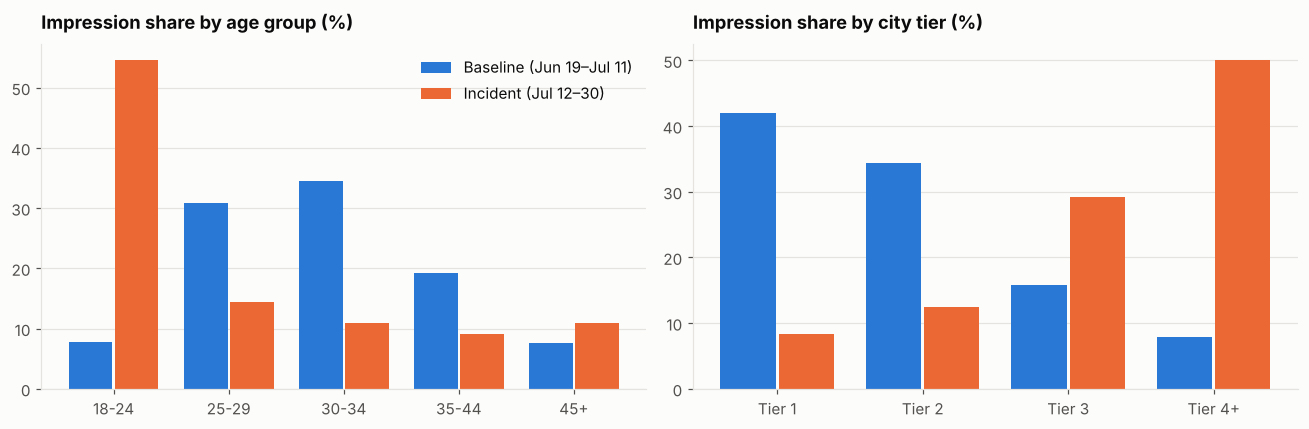

In [8]:
age_share = mix.groupby(["period", "age_group"])["impressions"].sum().unstack(0)
age_share = age_share / age_share.sum() * 100
tier_share = mix.groupby(["period", "city_tier"])["impressions"].sum().unstack(0)
tier_share = tier_share / tier_share.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tbl, title in [(axes[0], age_share, "Impression share by age group (%)"),
                       (axes[1], tier_share, "Impression share by city tier (%)")]:
    x = np.arange(len(tbl))
    w = 0.38
    ax.bar(x - w / 2 - 0.01, tbl["baseline"], w, color=ps.BLUE, label="Baseline (Jun 19–Jul 11)")
    ax.bar(x + w / 2 + 0.01, tbl["anomaly"], w, color=ps.ORANGE, label="Incident (Jul 12–30)")
    ax.set_xticks(x, tbl.index)
    ax.set_title(title)
axes[0].legend(loc="upper right")
fig.tight_layout()
ps.save(fig, "02_c03_audience_shift")

During the incident the share of impressions going to **18–24-year-olds jumped from ~8% to ~55%**, and
**Tier 3/4+ cities from ~24% to ~79%** — the opposite of a retargeting campaign aimed at the store's core
25–34, Tier 1–2 visitors.

## 5. Decomposing the CTR drop: audience mix vs. within-audience performance

Overall CTR = Σ (impression share × audience CTR). The change splits into:
- **Mix effect** — Σ Δshare × baseline CTR (traffic moved to different audiences)
- **Rate effect** — Σ baseline share × ΔCTR (the same audiences clicked less)
- **Interaction** — the remainder

In [9]:
s0, s1 = share["baseline"] / 100, share["anomaly"] / 100
c0, c1 = ctr["baseline"], ctr["anomaly"]
overall0, overall1 = (s0 * c0).sum(), (s1 * c1).sum()
decomp = pd.Series({
    "Baseline CTR (%)": overall0,
    "Mix effect": ((s1 - s0) * c0).sum(),
    "Rate effect": (s0 * (c1 - c0)).sum(),
    "Interaction": ((s1 - s0) * (c1 - c0)).sum(),
    "Incident CTR (%)": overall1,
}).round(3)
decomp

Baseline CTR (%)    3.347
Mix effect         -1.243
Rate effect         0.032
Interaction        -0.074
Incident CTR (%)    2.063
dtype: float64

In [10]:
total_drop = overall1 - overall0
print(f"CTR change: {total_drop:+.2f} pts; mix effect explains {decomp['Mix effect'] / total_drop:.0%} of it")

CTR change: -1.28 pts; mix effect explains 97% of it


**Root cause:** almost the entire CTR drop is a **mix effect** — within each audience, CTR barely moved.
The campaign's audience targeting was changed (e.g. auto-expansion switched on / a wrong audience package
attached), pushing budget to low-intent audiences. Creative, bids and the landing page were not the
problem. Restoring the original targeting on Jul 31 brought CTR straight back.

## 6. Business impact

In [11]:
base = mix[mix["period"] == "baseline"][["impressions", "clicks", "orders", "spend", "gmv"]].sum()
anom = mix[mix["period"] == "anomaly"][["impressions", "clicks", "orders", "spend", "gmv"]].sum()
impact = pd.DataFrame({"baseline (23 days)": base, "incident (19 days)": anom})
impact.loc["CTR %"] = impact.loc["clicks"] / impact.loc["impressions"] * 100
impact.loc["CVR %"] = impact.loc["orders"] / impact.loc["clicks"] * 100
impact.loc["ROAS"] = impact.loc["gmv"] / impact.loc["spend"]
display(impact.round(2))

expected_gmv = anom["spend"] * base["gmv"] / base["spend"]
expected_orders = anom["spend"] * base["orders"] / base["spend"]
print(f"Spend during incident: ¥{anom['spend']:,.0f}")
print(f"GMV at baseline ROAS would have been ¥{expected_gmv:,.0f}; actual ¥{anom['gmv']:,.0f}")
print(f"Lost GMV ≈ ¥{expected_gmv - anom['gmv']:,.0f}; lost orders ≈ {expected_orders - anom['orders']:,.0f}")

,baseline (23 days),incident (19 days)
impressions,605703.00,893328.00
clicks,20275.00,18424.00
orders,1317.00,696.00
spend,25531.29,21349.17
gmv,143774.71,73139.40
CTR %,3.35,2.06
CVR %,6.50,3.78
ROAS,5.63,3.43


Spend during incident: ¥21,349
GMV at baseline ROAS would have been ¥120,224; actual ¥73,139
Lost GMV ≈ ¥47,084; lost orders ≈ 405


## Recommendations
1. **Lock targeting on retargeting campaigns** and require a second reviewer for audience changes.
2. **Keep the daily CTR-drop alert running** (SQL above) — this incident would have been caught on day 1
   instead of after ~3 weeks.
3. **Monitor tracking health separately** (spend > 0 with 0 clicks) so data outages are not mistaken for
   performance problems.